# Week 4 · Task 3 — Worst-case inspection

For each arm, look at the **10 lowest-Dice test images** and describe what goes wrong. The patterns feed the Limitations section.

**Arms inspected:** SAM 3 `box-gt` (oracle), `box-j10` (realistic), `pt-3`; U-Net at 10 % and 100 % of the training data.

**Conventions.**
- SAM 3 arms: ranked by the single Dice per image in `per_image_results.csv`.
- U-Net arms: ranked by the **seed-mean** Dice per image (3 seeds). Panels show the **seed 0** prediction, labelled with both its own Dice and the seed-mean.
- Failure types are assigned by fixed rules (below) from the predicted mask, so the tally is reproducible. They are descriptive labels, not tests.
- Nothing here changes `results/per_image_results.csv`.

**Failure-type rules (applied in this order).**
1. `empty`: the predicted mask has no foreground pixels.
2. `no overlap`: prediction non-empty but Dice < 0.1.
3. `over-segmentation`: precision + 0.2 < recall (prediction much larger than the polyp).
4. `under-segmentation`: recall + 0.2 < precision (prediction covers only part of the polyp).
5. `boundary / other`: everything else.

In [1]:
from pathlib import Path
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "results" / "week4"
OUT.mkdir(parents=True, exist_ok=True)

N_WORST = 10
SMALL_CUT = 5.0     # % of image area, same small bin as Task 1.1

# label -> (arm, run_id or bracket)
ARMS = {
    "SAM3 box-gt":  ("sam3", "box-gt"),
    "SAM3 box-j10": ("sam3", "box-j10"),
    "SAM3 pt-3":    ("sam3", "pt-3"),
    "U-Net 10%":    ("unet", "10pct"),
    "U-Net 100%":   ("unet", "100pct"),
}

df = pd.read_csv(ROOT / "results" / "per_image_results.csv")
test_ids = [l.strip() for l in open(ROOT / "data" / "splits" / "test.txt") if l.strip() and not l.startswith("#")]
assert len(test_ids) == 200 and set(df.image_id) == set(test_ids)
print(df.groupby("arm").size().to_dict())

{'sam3': 1000, 'unet': 2400}


## 1. Per-arm tables: one row per image

In [2]:
def arm_table(label):
    arm, key = ARMS[label]
    cols = ["dice", "iou", "boundary_iou", "hd95", "precision", "recall"]
    if arm == "sam3":
        t = df[(df.arm == "sam3") & (df.run_id == key)].set_index("image_id")
        out = t[["gt_area_pct"] + cols].copy()
        out["dice_seed0"] = out["dice"]
    else:
        u = df[df.arm == "unet"].copy()
        u["bracket"] = u.run_id.str.extract(r"^(.+?)[_-]seed\d+$")[0]
        u = u[u.bracket == key]
        assert u.groupby("image_id").size().eq(3).all(), "expected 3 seeds per image"
        g = u.groupby("image_id")
        out = g[cols].mean()
        out["gt_area_pct"] = g["gt_area_pct"].first()
        out["dice_seed0"] = u[u.run_id == f"{key}_seed0"].set_index("image_id")["dice"]
    out["arm"] = label
    assert len(out) == 200
    return out

tables = {lab: arm_table(lab) for lab in ARMS}
worst = {lab: t.sort_values("dice").head(N_WORST) for lab, t in tables.items()}
for lab, w in worst.items():
    print(lab, "worst-10 Dice range: %.3f to %.3f" % (w.dice.min(), w.dice.max()))

SAM3 box-gt worst-10 Dice range: 0.000 to 0.513
SAM3 box-j10 worst-10 Dice range: 0.000 to 0.098
SAM3 pt-3 worst-10 Dice range: 0.039 to 0.420
U-Net 10% worst-10 Dice range: 0.000 to 0.308
U-Net 100% worst-10 Dice range: 0.000 to 0.490


## 2. Load masks and tag failure types

Prediction paths: `results/sam3_preds/<prompt>/<id>.png` and `results/unet_preds/<bracket>_seed0/<id>.png` (both binary, native resolution).

In [3]:
def load_image(i):
    img = cv2.imread(str(ROOT / "data/kvasir-seg/images" / f"{i}.jpg"))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_gt(i):
    m = cv2.imread(str(ROOT / "data/kvasir-seg/masks" / f"{i}.jpg"), cv2.IMREAD_GRAYSCALE)
    return m > 127

def load_pred(label, i):
    arm, key = ARMS[label]
    p = ROOT / "results/sam3_preds" / key / f"{i}.png" if arm == "sam3" else ROOT / "results/unet_preds" / f"{key}_seed0" / f"{i}.png"
    m = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    assert m is not None, p
    return m > 127

def failure_type(pred, row):
    if pred.sum() == 0:
        return "empty"
    if row.dice < 0.1:
        return "no overlap"
    if row.precision + 0.2 < row.recall:
        return "over-segmentation"
    if row.recall + 0.2 < row.precision:
        return "under-segmentation"
    return "boundary / other"

records = []
for lab, w in worst.items():
    for rank, (i, r) in enumerate(w.iterrows(), start=1):
        pred = load_pred(lab, i)
        records.append({
            "arm": lab, "rank": rank, "image_id": i, "gt_area_pct": round(r.gt_area_pct, 2),
            "dice_mean": round(r.dice, 3), "dice_seed0": round(r.dice_seed0, 3),
            "precision": round(r.precision, 3), "recall": round(r.recall, 3),
            "pred_area_pct": round(100 * pred.mean(), 2),
            "type": failure_type(pred, r),
        })
worst_df = pd.DataFrame(records)
worst_df.to_csv(OUT / "worst10_all_arms.csv", index=False)
worst_df

,arm,rank,image_id,gt_area_pct,dice_mean,dice_seed0,precision,recall,pred_area_pct,type
0,SAM3 box-gt,1,cju3518w2d838079939fqztbc,17.03,0.000,0.000,0.000,0.000,12.13,no overlap
1,SAM3 box-gt,2,cju2ysg748ru80878sp6j0gm0,30.49,0.000,0.000,0.000,0.000,12.73,no overlap
2,SAM3 box-gt,3,cju8b1v3br45u087189kku66u,24.50,0.010,0.010,0.010,0.010,25.25,no overlap
3,SAM3 box-gt,4,cju1fuoa4wmc50835qfd11sp9,8.19,0.106,0.106,0.064,0.323,41.59,over-segmentation
4,SAM3 box-gt,5,cju8abobpqbir08189u01huru,10.77,0.336,0.336,0.204,0.939,49.47,over-segmentation
5,SAM3 box-gt,6,cju5yeqiwmkgl0801fzv2douc,20.69,0.445,0.445,0.879,0.298,7.01,under-segmentation
6,SAM3 box-gt,7,cju7ddtz729960801uazp1knc,17.25,0.468,0.468,0.316,0.901,49.09,over-segmentation
7,SAM3 box-gt,8,cju7fpfzq2wyf0818xxd1oziv,20.67,0.489,0.489,0.397,0.634,32.97,over-segmentation
8,SAM3 box-gt,9,cju5nxkujgscq0817l9gss626,16.02,0.491,0.491,0.439,0.558,20.38,boundary / other
9,SAM3 box-gt,10,cju34repocy5208780gswillm,22.41,0.513,0.513,0.377,0.799,47.41,over-segmentation


## 3. Patterns across arms

In [4]:
overall_median_area = tables["SAM3 box-gt"].gt_area_pct.median()
rows = []
for lab in ARMS:
    w = worst_df[worst_df.arm == lab]
    rows.append({
        "arm": lab,
        "median GT area % (worst 10)": w.gt_area_pct.median(),
        "n small (<5%)": int((w.gt_area_pct < SMALL_CUT).sum()),
        **{t: int((w.type == t).sum()) for t in ["empty", "no overlap", "over-segmentation", "under-segmentation", "boundary / other"]},
    })
summary = pd.DataFrame(rows).set_index("arm")
print("Median GT area over all 200 test images: %.2f %%; share of small polyps: %.1f %%" % (
    overall_median_area, 100 * (tables["SAM3 box-gt"].gt_area_pct < SMALL_CUT).mean()))
summary.to_csv(OUT / "worst10_pattern_summary.csv")
summary

Median GT area over all 200 test images: 11.87 %; share of small polyps: 19.5 %


,median GT area % (worst 10),n small (<5%),empty,no overlap,over-segmentation,under-segmentation,boundary / other
arm,,,,,,,
SAM3 box-gt,18.960,0,0,3,5,1,1
SAM3 box-j10,19.230,0,0,10,0,0,0
SAM3 pt-3,15.225,3,0,1,6,3,0
U-Net 10%,1.690,8,0,3,4,1,2
U-Net 100%,1.635,8,2,0,3,3,2


In [5]:
# Which images are hard for several arms?
sets = {lab: set(worst_df[worst_df.arm == lab].image_id) for lab in ARMS}
counts = pd.Series([i for s in sets.values() for i in s]).value_counts()
shared = counts[counts >= 2]
print("Images in the worst 10 of at least 2 arms:", len(shared))
print(shared.to_string())
print()
labs = list(ARMS)
overlap = pd.DataFrame([[len(sets[a] & sets[b]) for b in labs] for a in labs], index=labs, columns=labs)
overlap

Images in the worst 10 of at least 2 arms: 14
cju89z6pqpqfx0817mfv8ixjc    3
cju5yeqiwmkgl0801fzv2douc    3
cju15l5ubz9yh0855b3ivdpse    3
cju6vvb8svhed0801jjcquh5e    3
cju3518w2d838079939fqztbc    2
cju1fuoa4wmc50835qfd11sp9    2
cju8abobpqbir08189u01huru    2
cju7fpfzq2wyf0818xxd1oziv    2
cju2wxv0hxs2f09884w48v8fi    2
cju2hugv9vget0799hhk7ksvg    2
cju5nxkujgscq0817l9gss626    2
cju0tl3uz8blh0993wxvn7ly3    2
cju8b1v3br45u087189kku66u    2
cju3ykamdj9u208503pygyuc8    2



,SAM3 box-gt,SAM3 box-j10,SAM3 pt-3,U-Net 10%,U-Net 100%
SAM3 box-gt,10,6,1,0,1
SAM3 box-j10,6,10,0,0,0
SAM3 pt-3,1,0,10,3,4
U-Net 10%,0,0,3,10,7
U-Net 100%,1,0,4,7,10


## 4. Panels (image | GT outline | prediction with GT outline)

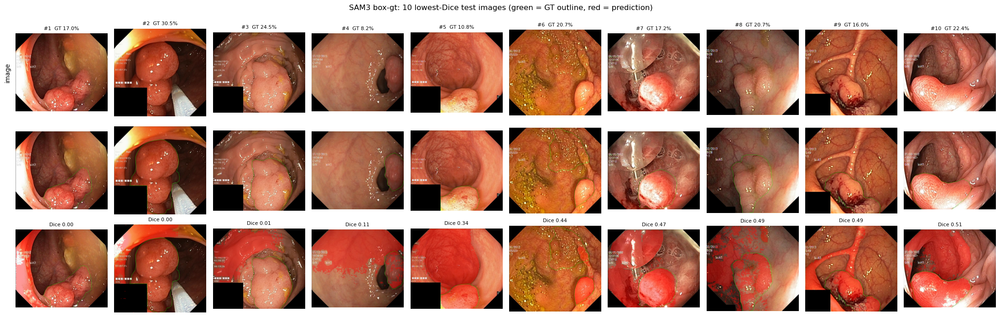

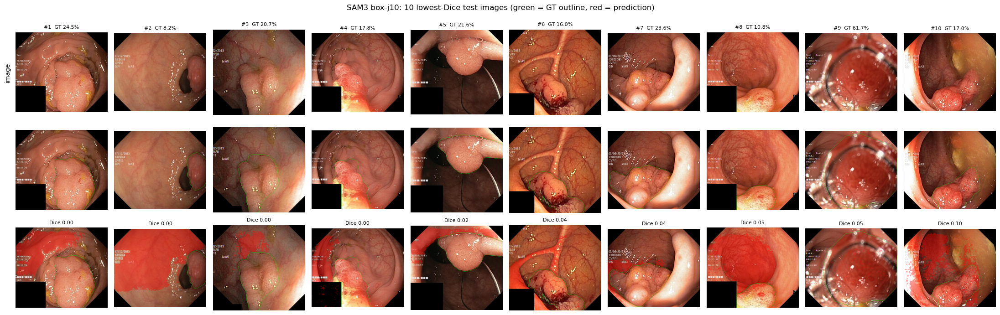

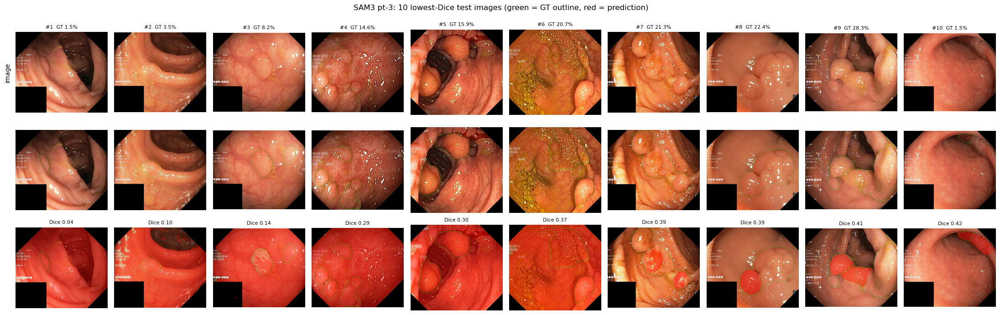

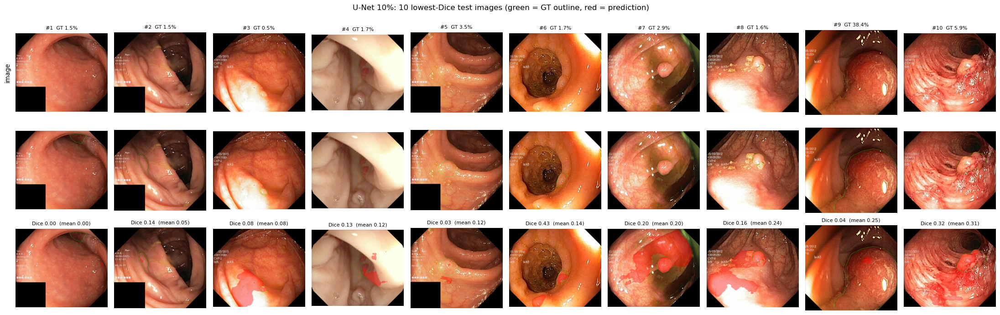

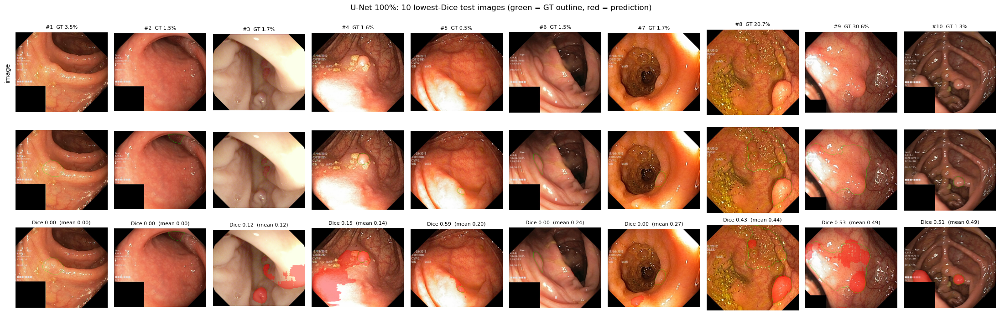

In [6]:
def outline(mask):
    m = mask.astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    return (m - cv2.erode(m, k)).astype(bool)

def panel(lab):
    w = worst[lab]
    fig, axes = plt.subplots(3, N_WORST, figsize=(2.2 * N_WORST, 7))
    for c, (i, r) in enumerate(w.iterrows()):
        img, gt, pred = load_image(i), load_gt(i), load_pred(lab, i)
        gt_o = outline(gt)
        a = axes[0, c]; a.imshow(img); a.set_title(f"#{c+1}  GT {r.gt_area_pct:.1f}%", fontsize=8)
        b = axes[1, c]; ov = img.copy(); ov[gt_o] = (0, 255, 0); b.imshow(ov)
        d = axes[2, c]; ov2 = img.copy(); ov2[pred & ~gt_o] = (0.6 * ov2[pred & ~gt_o] + 0.4 * np.array([255, 0, 0])).astype(np.uint8)
        ov2[gt_o] = (0, 255, 0); d.imshow(ov2)
        d.set_title(f"Dice {r.dice_seed0:.2f}  (mean {r.dice:.2f})" if lab.startswith("U-Net") else f"Dice {r.dice:.2f}", fontsize=8)
        for ax in (a, b, d): ax.axis("off")
    axes[0, 0].text(-0.05, 0.5, "image", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center")
    fig.suptitle(f"{lab}: 10 lowest-Dice test images (green = GT outline, red = prediction)", y=0.995)
    fig.tight_layout()
    fname = OUT / ("worst10_" + re.sub(r"[^A-Za-z0-9]+", "_", lab).strip("_") + ".png")
    fig.savefig(fname, dpi=130, bbox_inches="tight")
    return fig

for lab in ARMS:
    panel(lab)
    plt.show()

## 5. Notes for the Limitations section

- **SAM 3, oracle box (`box-gt`):** All 10 worst cases are medium or large polyps (GT 8–31 % of the image; none under 5 %). The dominant pattern is SAM 3 returning a large region of surrounding mucosa instead of the polyp, even though the box is tight (Dice 0.00 to 0.11 for ranks 1–4; tags: 5 over-segmentation, 3 no overlap). The failing polyps are pale or similar in colour to the wall, large, or partly cut by the field-of-view edge. Rank 2 is unclear from the panel: confirm in the raw mask (`results/sam3_preds/box-gt/cju2ysg748ru80878sp6j0gm0.png`).
- **SAM 3, jittered box (`box-j10`):** All 10 worst cases are no-overlap (Dice 0.00 to 0.10), all medium or large (8–62 %). Perturbing a large box by ±10 % makes it include a lot of wall, and SAM 3 then segments the wall or nothing. Six of the 10 images are also in the `box-gt` worst 10, so these polyps are hard for SAM 3 even with perfect localisation.
- **SAM 3, 3 points (`pt-3`):** Two patterns. (a) Over-segmentation of most of the field of view (6 of 10, ranks 1–6), including small polyps (1.5–3.5 %). (b) Under-segmentation of multi-lobed lesions: the prediction covers one or two lobes only (ranks 7–9, GT 21–28 %). One small polyp (1.5 %) has its mask in the wrong place at the image edge.
- **U-Net 10 %:** 8 of the 10 worst are small polyps (0.5–3.5 %, median 1.7 %). Typical failures: the small polyp is missed and a blob appears elsewhere, often on bright glare or specular patches; one large polyp (38 %) is almost entirely missed. Seed disagreement is large (e.g. rank 6: seed 0 Dice 0.43, seed mean 0.14), so the panel shows one seed only.
- **U-Net 100 %:** Same population (8 of 10 small, median 1.6 %); 7 of its 10 worst are also in the 10 % worst 10, so more data did not fix the same images. Two predictions are empty (Dice 0.00, 1.5–3.5 % polyps), and two more are empty for seed 0 only. Several false positives sit on white glare patches or on other bumps that look like polyps (ranks 7, 8, 10). Possibly unannotated polyp-like structures; check.
- **Shared failures:** 14 images are in the worst 10 of at least two arms; 4 are in three. Three of those 4 are small polyps (1.5–3.5 %) that defeat `pt-3` and the U-Net at both brackets. The fourth is a large polyp (20.7 %, yellowish mucosa with bubbles) that defeats `box-gt`, `pt-3` and the 100 % U-Net.
- **Complementary failure modes:** The box-prompted SAM 3 failures (large, featureless or low-contrast polyps) and the U-Net failures (small polyps) are almost disjoint populations: `box-gt`/`box-j10` share 0–1 images with the U-Net arms. This fits the size-stratified result (SAM 3 ahead on small polyps, U-Net catching up on large).
- **Small polyps:** The U-Net's weakness: low Dice, empty predictions, and glare false positives. SAM 3 with points is not immune, with 3 of its 10 worst below 5 %.
- **Annotation and image artefacts:** The black lower-left box with overlaid text appears in many of the failing images, but it is present in many Kvasir images generally, so don't claim it causes failures. Glare and specular highlights are linked to U-Net false positives. Some failures may reflect ground-truth ambiguity, because the annotated polyp is sometimes not the most polyp-like structure in view.